## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Armon Haji

**Date:** 10/14/2026

In [7]:
# Your Phase 1 solution to the problem goes here.

import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100)
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])

    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})

    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

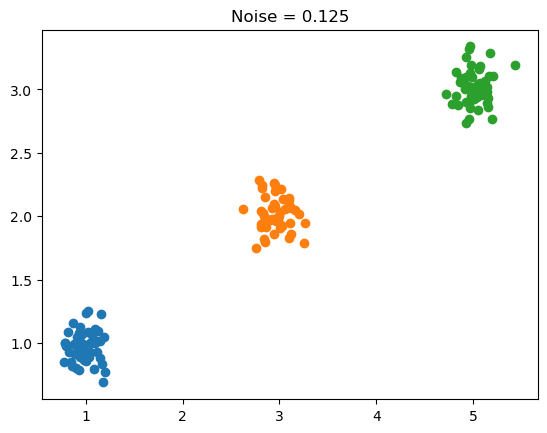

In [8]:
import matplotlib.pyplot as plt

plt.scatter(df0_125[df0_125["group"]=="a"]["x1"], df0_125[df0_125["group"]=="a"]["x2"])
plt.scatter(df0_125[df0_125["group"]=="b"]["x1"], df0_125[df0_125["group"]=="b"]["x2"])
plt.scatter(df0_125[df0_125["group"]=="c"]["x1"], df0_125[df0_125["group"]=="c"]["x2"])
plt.title("Noise = 0.125")
plt.show()

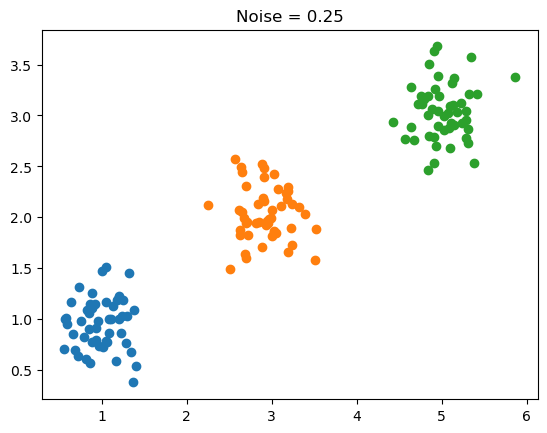

In [9]:
plt.scatter(df0_25[df0_25["group"]=="a"]["x1"], df0_25[df0_25["group"]=="a"]["x2"])
plt.scatter(df0_25[df0_25["group"]=="b"]["x1"], df0_25[df0_25["group"]=="b"]["x2"])
plt.scatter(df0_25[df0_25["group"]=="c"]["x1"], df0_25[df0_25["group"]=="c"]["x2"])
plt.title("Noise = 0.25")
plt.show()

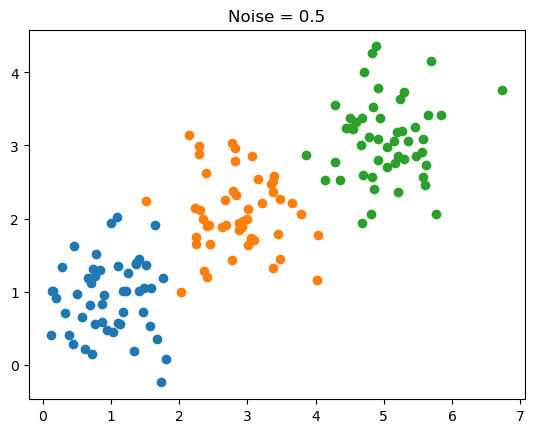

In [10]:
plt.scatter(df0_5[df0_5["group"]=="a"]["x1"], df0_5[df0_5["group"]=="a"]["x2"])
plt.scatter(df0_5[df0_5["group"]=="b"]["x1"], df0_5[df0_5["group"]=="b"]["x2"])
plt.scatter(df0_5[df0_5["group"]=="c"]["x1"], df0_5[df0_5["group"]=="c"]["x2"])
plt.title("Noise = 0.5")
plt.show()

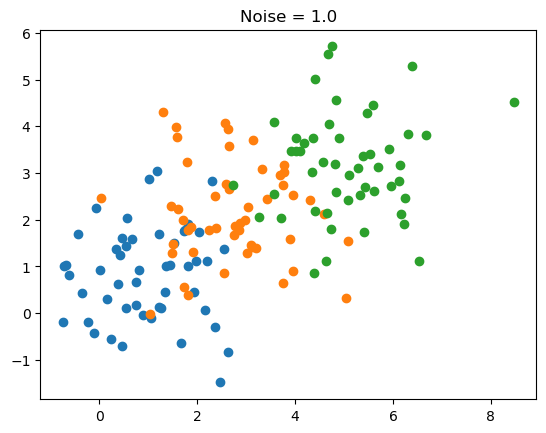

In [11]:
plt.scatter(df1_0[df1_0["group"]=="a"]["x1"], df1_0[df1_0["group"]=="a"]["x2"])
plt.scatter(df1_0[df1_0["group"]=="b"]["x1"], df1_0[df1_0["group"]=="b"]["x2"])
plt.scatter(df1_0[df1_0["group"]=="c"]["x1"], df1_0[df1_0["group"]=="c"]["x2"])
plt.title("Noise = 1.0")
plt.show()

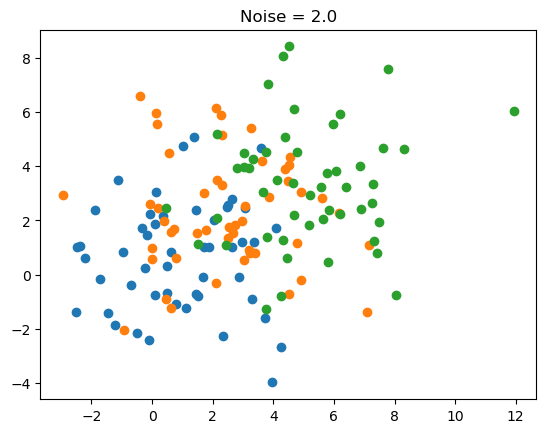

In [12]:
plt.scatter(df2_0[df2_0["group"]=="a"]["x1"], df2_0[df2_0["group"]=="a"]["x2"])
plt.scatter(df2_0[df2_0["group"]=="b"]["x1"], df2_0[df2_0["group"]=="b"]["x2"])
plt.scatter(df2_0[df2_0["group"]=="c"]["x1"], df2_0[df2_0["group"]=="c"]["x2"])
plt.title("Noise = 2.0")
plt.show()

In [13]:
## We can see on the charts that as the noise increases, the clusters become more spread out. They 
## also start to overlap more. While the  lower noise levels the three groups are easy to tell apart, 
## once you reach the noise 1.0 and 2.0 the groups are much less distinct.

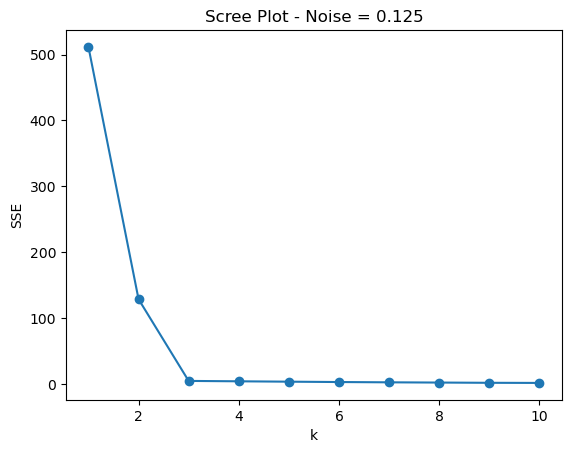

In [14]:
from sklearn.cluster import KMeans

sse = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=0, n_init=10)
    model.fit(df0_125[["x1", "x2"]])
    sse.append(model.inertia_)

plt.plot(range(1, 11), sse, marker="o")
plt.title("Scree Plot - Noise = 0.125")
plt.xlabel("k")
plt.ylabel("SSE")
plt.show()

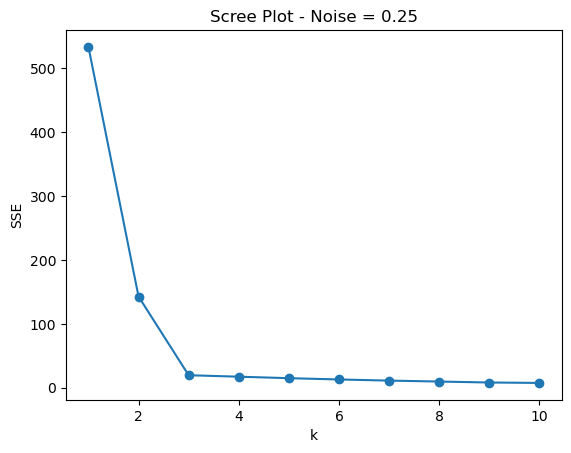

In [15]:
sse = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=0, n_init=10)
    model.fit(df0_25[["x1", "x2"]])
    sse.append(model.inertia_)

plt.plot(range(1, 11), sse, marker="o")
plt.title("Scree Plot - Noise = 0.25")
plt.xlabel("k")
plt.ylabel("SSE")
plt.show()

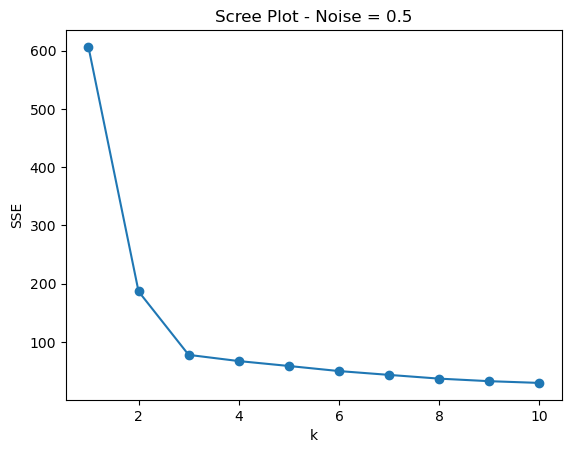

In [16]:
sse = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=0, n_init=10)
    model.fit(df0_5[["x1", "x2"]])
    sse.append(model.inertia_)

plt.plot(range(1, 11), sse, marker="o")
plt.title("Scree Plot - Noise = 0.5")
plt.xlabel("k")
plt.ylabel("SSE")
plt.show()

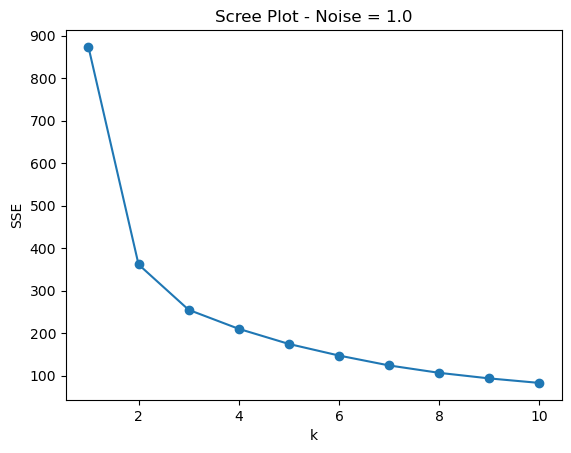

In [17]:
sse = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=0, n_init=10)
    model.fit(df1_0[["x1", "x2"]])
    sse.append(model.inertia_)

plt.plot(range(1, 11), sse, marker="o")
plt.title("Scree Plot - Noise = 1.0")
plt.xlabel("k")
plt.ylabel("SSE")
plt.show()

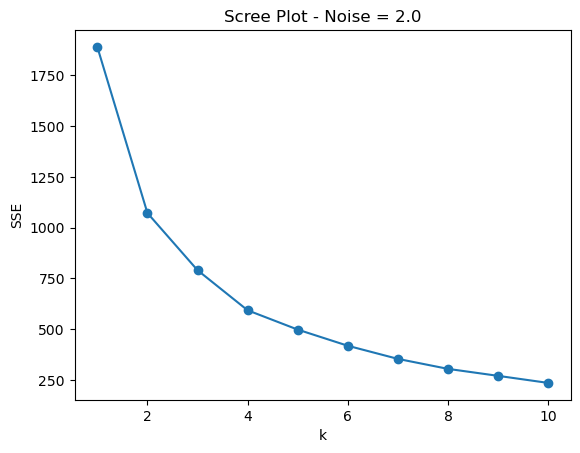

In [18]:
sse = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=0, n_init=10)
    model.fit(df2_0[["x1", "x2"]])
    sse.append(model.inertia_)

plt.plot(range(1, 11), sse, marker="o")
plt.title("Scree Plot - Noise = 2.0")
plt.xlabel("k")
plt.ylabel("SSE")
plt.show()

In [19]:
## We can see that through the exhibits that as the noise increases, the elbow in the scree plot 
## becomes less clear. It appears that at lower noise levels, k = 3 is easy to identify because the 
## SSE drops sharply up to 3 and then plateaus. off. At higher noise levels, the curve is smoother, 
## so this makes it harder for us to confidently choose k.

In [ ]:
## This elbow actually happens because of the fact that adding more clusters lowers the SSE a lot at first. Once we get around the
## actual main groups, adding more clusters doesn't help nearly as much anymore. In the lower noise data this happens around k = 3 because 
## there are three pretty clear groups.

In [20]:
sipri = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")
sipri2020 = sipri[sipri["Year"] == 2020]
sipri2020 = sipri2020.dropna()
sipri2020.shape

(148, 7)

In [21]:
sipri2020.dtypes

index                               int64
Year                                int64
Country                               str
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object

In [22]:
## The variables we need are already numeric. We don't need to do any more cleaning.

In [23]:
sipri2020["Spending_norm"] = (
    sipri2020["Spending (2020 USD)"] - sipri2020["Spending (2020 USD)"].min()
) / (
    sipri2020["Spending (2020 USD)"].max() - sipri2020["Spending (2020 USD)"].min()
)

sipri2020["PerCapita_norm"] = (
    sipri2020["Spending per Capita"] - sipri2020["Spending per Capita"].min()
) / (
    sipri2020["Spending per Capita"].max() - sipri2020["Spending per Capita"].min()
)

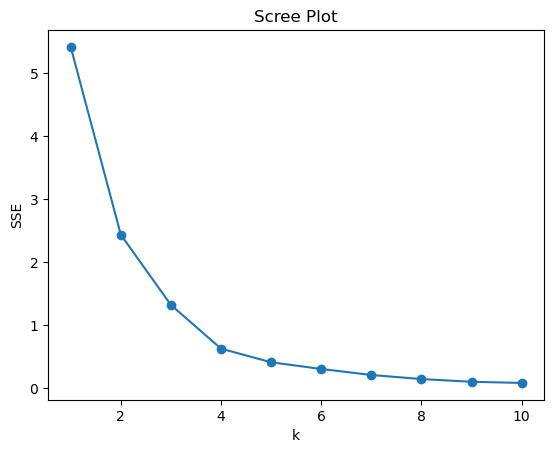

In [24]:
sse = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=0, n_init=10)
    model.fit(sipri2020[["Spending_norm", "PerCapita_norm"]])
    sse.append(model.inertia_)
plt.plot(range(1, 11), sse, marker="o")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Scree Plot")
plt.show()

In [25]:
model = KMeans(n_clusters=4, random_state=0, n_init=10)
sipri2020["cluster"] = model.fit_predict(
    sipri2020[["Spending_norm", "PerCapita_norm"]]
)

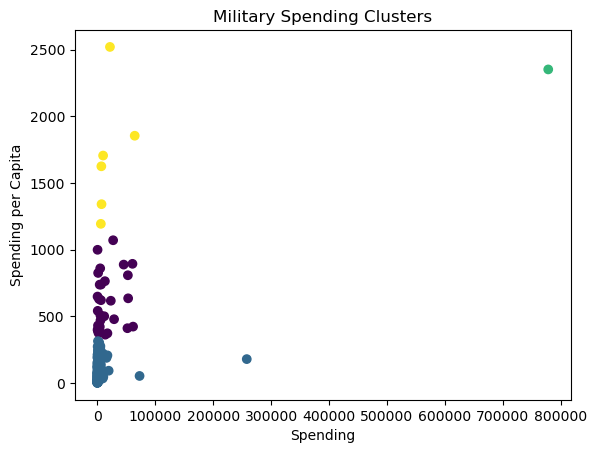

In [26]:
plt.scatter(
    sipri2020["Spending (2020 USD)"],
    sipri2020["Spending per Capita"],
    c=sipri2020["cluster"]
)

plt.xlabel("Spending")
plt.ylabel("Spending per Capita")
plt.title("Military Spending Clusters")
plt.show()

In [27]:
sipri2020.groupby("cluster")[["Spending (2020 USD)", "Spending per Capita"]].describe()

Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      30.0   17077.591354  20583.053357     405.790494   
1                     111.0    4859.185065  25405.739131       8.622460   
2                       1.0  778397.200000           NaN  778397.200000   
3                       6.0   19443.362047  22861.507114    6095.708713   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          2294.039665    5857.060906   26296.001003   61712.537169   
1           130.010211     382.464677    2297.032353  257973.429834   
2        778397.200000  778397.200000  778397.200000  778397.200000   
3          7023.251766    8624.225729   18857.070183   64558.400000   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                      30.0   607.478618  206.928757   362.467076   
1                     111.0    80.061470   83.501824     0.580129   
2                       1.0  2351.631858         NaN  2351.631858   
3                       6.0  1706.721916  466.375705  1193.598730   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0         422.208252   579.004604   757.328513  1070.623322  
1          14.880549    47.056944   125.387558   314.201312  
2        2351.631858  2351.631858  2351.631858  2351.631858  
3        1412.083201  1665.447478  1817.219993  2520.398541

In [28]:
sipri2020[sipri2020["Country"].str.contains("United", case=False)]

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,Spending_norm,PerCapita_norm,cluster
5506,5506,2020,United Kingdom,60675.039625,0.022408,0.045629,893.778388,0.077938,0.354469,0
5540,5540,2020,United States of America,778397.200000,0.037179,0.081976,2351.631858,1.000000,0.933024,2


In [29]:
## These clusters tell a pretty clear story up front. There is a difference between countries with lower spending and countries with much 
## higher spending. The United States is in cluster 2 by itself mainly due to the fact that its military spending is much higher than the 
## other countries. Some other clusters seem to group countries that have higher spending per capita even if their total spending is not as 
## extreme.

In [30]:
sipri2020["GovSpend_norm"] = (sipri2020["Percent of Government Spending"] - sipri2020["Percent of Government Spending"].min()) / (sipri2020["Percent of Government Spending"].max() - sipri2020["Percent of Government Spending"].min())

sipri2020["GDP_norm"] = (sipri2020["Percent of GDP"] - sipri2020["Percent of GDP"].min()) / (sipri2020["Percent of GDP"].max() - sipri2020["Percent of GDP"].min())

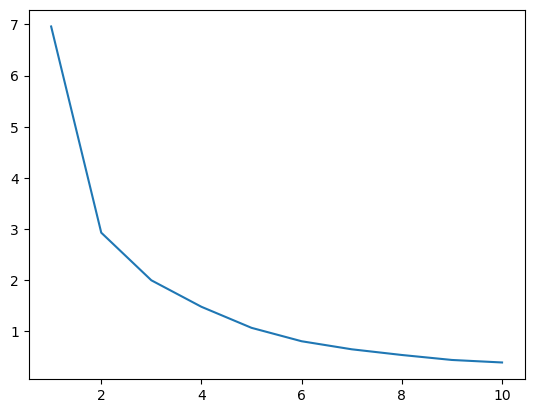

In [31]:
sse = []

for k in range(1,11):
    m = KMeans(n_clusters=k, random_state=0, n_init=10)
    m.fit(sipri2020[["GovSpend_norm","GDP_norm"]])
    sse.append(m.inertia_)

plt.plot(range(1,11), sse)
plt.show()

In [32]:
m = KMeans(n_clusters=3, random_state=0, n_init=10)

sipri2020["cluster2"] = m.fit_predict(
    sipri2020[["GovSpend_norm","GDP_norm"]]
)

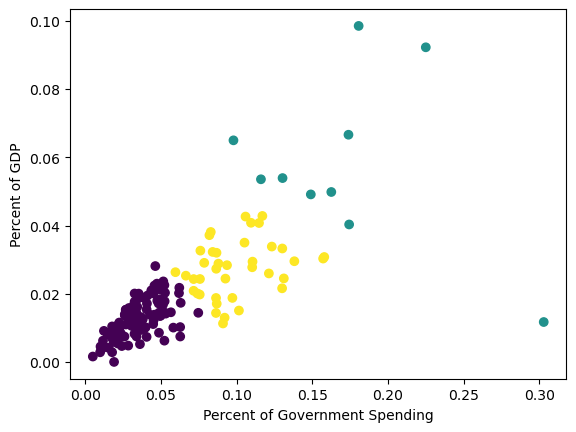

In [33]:
plt.scatter(
    sipri2020["Percent of Government Spending"],
    sipri2020["Percent of GDP"],
    c=sipri2020["cluster2"]
)

plt.xlabel("Percent of Government Spending")
plt.ylabel("Percent of GDP")
plt.show()

In [34]:
sipri2020.groupby("cluster2")[["Percent of Government Spending", "Percent of GDP"]].describe()

Percent of Government Spending                                \
                                  count      mean       std       min   
cluster2                                                                
0                                  99.0  0.035777  0.014549  0.004896   
1                                  10.0  0.171289  0.058725  0.097882   
2                                  39.0  0.098683  0.024125  0.059520   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster2                                                                    
0         0.025921  0.034261  0.047402  0.074624           99.0  0.012664   
1         0.135010  0.168248  0.179081  0.303027           10.0  0.058071   
2         0.082430  0.092044  0.112633  0.157918           39.0  0.027412   

                                                                      
               std       min       25%       50%       75%       max  
cluster2                                                              
0         0.005681  0.000054  0.008393  0.013191  0.016752  0.028132  
1         0.024867  0.011742  0.049297  0.053729  0.066190  0.098470  
2         0.008191  0.011317  0.021254  0.027781  0.032461  0.042810

In [89]:
sipri2020[sipri2020["Country"].str.contains("United States", case=False)][
    ["Country", "Percent of Government Spending", "Percent of GDP", "cluster2"]
]

,Country,Percent of Government Spending,Percent of GDP,cluster2
5540,United States of America,0.081976,0.037179,2


In [35]:
## The percentage based clusters look pretty different from the spending clusters. This is because Cluster 0 has most of the countries with 
## lower percentages, cluster 2 has countries in the middle, and cluster 1 has the countries with the highest values. Compared to the first 
## clustering, this one appears to be influenced more on how important military spending is relative to each country's budget/economy 
## rather than justt about how many total dollars they spend. The United States is also in cluster 2 for this version.

In [36]:
all4 = sipri2020[["Spending_norm","PerCapita_norm","GovSpend_norm","GDP_norm"]]

In [37]:
m = KMeans(n_clusters=3, random_state=0, n_init=10)
sipri2020["cluster3"] = m.fit_predict(all4)

In [38]:
sipri2020.groupby("cluster3")[[
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]].describe()

Spending (2020 USD)                                             \
                       count           mean            std          min   
cluster3                                                                  
0                        6.0  147964.582042  309635.189564  6095.708713   
1                      111.0    7086.472777   26479.379918     8.622460   
2                       31.0    8786.086602   17901.909108   162.373364   

                                                                  \
                  25%           50%           75%            max   
cluster3                                                           
0         7700.424616  15897.570598  53872.942442  778397.200000   
1          130.010211    567.650747   3910.107493  257973.429834   
2          467.787851   1404.787234   7739.166193   72937.064048   

         Spending per Capita               ... Percent of Government Spending  \
                       count         mean  ...                            75%   
cluster3                                   ...                                  
0                        6.0  1875.150751  ...                       0.164503   
1                      111.0   196.926833  ...                       0.050505   
2                       31.0   212.689100  ...                       0.134663   

                   Percent of GDP                                          \
               max          count      mean       std       min       25%   
cluster3                                                                    
0         0.225050            6.0  0.062634  0.028275  0.029429  0.041272   
1         0.092044          111.0  0.013419  0.005996  0.000054  0.008873   
2         0.303027           31.0  0.033492  0.011449  0.011742  0.027560   

                                        
               50%       75%       max  
cluster3                                
0         0.059257  0.085398  0.098470  
1         0.013589  0.017769  0.028132  
2         0.032024  0.040531  0.066600  

[3 rows x 32 columns]

In [39]:
## Using all four of the variables gave us a mix of the patterns from the first two clusterings. One of these clusters contains countries 
## with much higher total spending and spending per capita. The other clusters separate countries more by how large military spending is 
## compared to things like the GDP and government spending. In my opinion, this method will give us more of a complete view than using only 
## two variables at a time.

In [40]:
## I think that k-means was useful because of the fact that it helped show groups of countries with similar military spending. Another 
## thing it did was make some extreme countries easier to notice, like the United States. The clusters are not perfect, but they do make the 
## data easier to compare.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [50]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]